## 1. Цель исследования

Классифицируем запись по корпусной метке диктора M/F. Единица наблюдения — фраза, единица разделения — диктор. Задачи: подготовить корпус, сравнить модели и проверить качество на новых голосах.

In [ ]:
print("Системы искусственного интеллекта и машинное обучение · Блок 4 · Вариант 47")

Системы искусственного интеллекта и машинное обучение · Блок 4 · Вариант 47


## 2. Среда и воспроизводимость

Перед первым запуском установите зависимости из requirements.txt в выбранное ядро. Пути вычисляются относительно каталога проекта. Обучение рассчитано на CPU.

In [2]:
from pathlib import Path
import hashlib, json, math, platform, tarfile, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal, fft
from sklearn import metrics
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, RES = ROOT/"data/raw", ROOT/"results"
FIG, TAB, MODEL = RES/"figures", RES/"tables", ROOT/"models/best_model.pth"
for directory in [RAW,FIG,TAB,MODEL.parent]:
    directory.mkdir(parents=True, exist_ok=True)
SEED = 47
torch.set_num_threads(2)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
print(platform.python_version(), torch.__version__, "CPU; доступность CUDA:", torch.cuda.is_available())

def figure(name):
    plt.tight_layout()
    plt.savefig(FIG/name, dpi=145, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(FIG/name)))

3.12.10 2.15.0+cpu CPU; доступность CUDA: False


## 3. Получение записей и проверка корпуса

Официальный раздел dev-clean используется как самостоятельный учебный корпус. Выбираем до 12 фраз каждого диктора по фиксированному случайному порядку. При наличии комплектной выборки сеть не требуется.

In [3]:
if not (RAW/"selection.csv").exists():
    archive = ROOT/"data/dev-clean.tar.gz"
    if not archive.exists():
        urllib.request.urlretrieve("https://www.openslr.org/resources/12/dev-clean.tar.gz", archive)
    with archive.open("rb") as stream:
        if hashlib.file_digest(stream,"md5").hexdigest() != "42e2234ba48799c1f50f24a7926300a1":
            raise ValueError("Архив повреждён. Удалите data/dev-clean.tar.gz и повторите запуск.")
    with tarfile.open(archive) as tf:
        speakers = tf.extractfile("LibriSpeech/SPEAKERS.TXT").read().decode()
        labels = {}
        for line in speakers.splitlines():
            if line.strip() and not line.startswith(";"):
                sid, label, subset, *_ = [v.strip() for v in line.split("|")]
                if subset=="dev-clean":
                    labels[sid]=label
        files = [m.name for m in tf if m.name.endswith(".flac")]
        rng = np.random.default_rng(SEED)
        selected = []
        for sid in sorted(labels):
            names = sorted(n for n in files if Path(n).stem.split("-")[0]==sid)
            for n in sorted(rng.choice(names, min(12,len(names)), replace=False)):
                selected.append(dict(file=Path(n).name, speaker=int(sid), label=labels[sid], source=n))
    # Потоковое чтение в порядке архива исключает повторную распаковку gzip.
    wanted = {r["source"]:r["file"] for r in selected}
    with tarfile.open(archive,"r|gz") as tf:
        for item in tf:
            if item.name in wanted:
                (RAW/wanted[item.name]).write_bytes(tf.extractfile(item).read())
    pd.DataFrame(selected).to_csv(RAW/"selection.csv",index=False)
df = pd.read_csv(RAW/"selection.csv")
def duration(file):
    x,sr=sf.read(RAW/file)
    if x.size==0 or not np.isfinite(x).all() or np.max(np.abs(x))==0:
        raise ValueError(f"Пустой или повреждённый сигнал: {file}")
    return len(x)/sr
df["seconds"]=df.file.map(duration)
assert df.file.is_unique and df.groupby("speaker").label.nunique().max()==1
display(df.head())

,file,speaker,label,source,seconds
0,1272-128104-0005.flac,1272,M,LibriSpeech/dev-clean/1272/128104/1272-128104-...,9.010
1,1272-128104-0006.flac,1272,M,LibriSpeech/dev-clean/1272/128104/1272-128104-...,5.640
2,1272-128104-0007.flac,1272,M,LibriSpeech/dev-clean/1272/128104/1272-128104-...,9.240
3,1272-135031-0008.flac,1272,M,LibriSpeech/dev-clean/1272/135031/1272-135031-...,3.670
4,1272-135031-0010.flac,1272,M,LibriSpeech/dev-clean/1272/135031/1272-135031-...,8.995


## 4. Первичный анализ

Длительности измеряем по декодированным отсчётам исходных файлов. Одинаковая квота фраз ограничивает влияние наиболее представленных дикторов.

,фраз,дикторов,мин,медиана,макс
label,,,,,
F,240,20,1.74,6.497531,24.03
M,240,20,1.85,6.670000,32.05


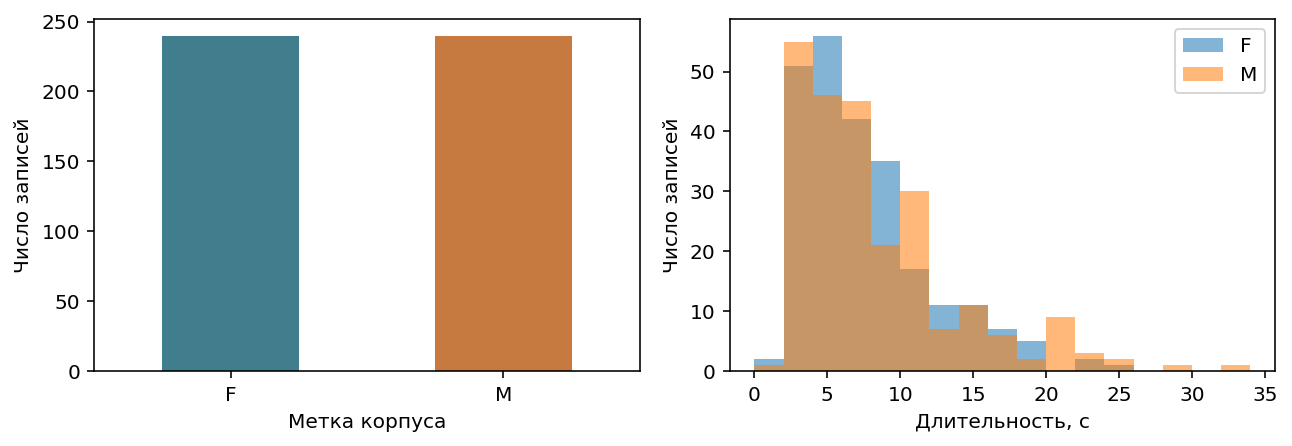

In [4]:
display(df.groupby("label").agg(фраз=("file","size"),дикторов=("speaker","nunique"),мин=("seconds","min"),медиана=("seconds","median"),макс=("seconds","max")))
fig, ax = plt.subplots(1,2,figsize=(9,3.2))
df.groupby("label").size().plot.bar(ax=ax[0],rot=0,color=["#417e8d","#c77a40"],ylabel="Число записей",xlabel="Метка корпуса")
for label,g in df.groupby("label"):
    ax[1].hist(g.seconds, bins=np.arange(0,df.seconds.max()+2,2),alpha=.55,label=label)
ax[1].set(xlabel="Длительность, с",ylabel="Число записей")
ax[1].legend()
figure("corpus.png")

## 5. Предобработка и аугментация

Используем центральные 2 секунды монофонического сигнала. Короткие фразы дополняем нулями. Для каждого обучающего примера создаём отдельную копию со слабым шумом, сдвигом и небольшим изменением скорости.

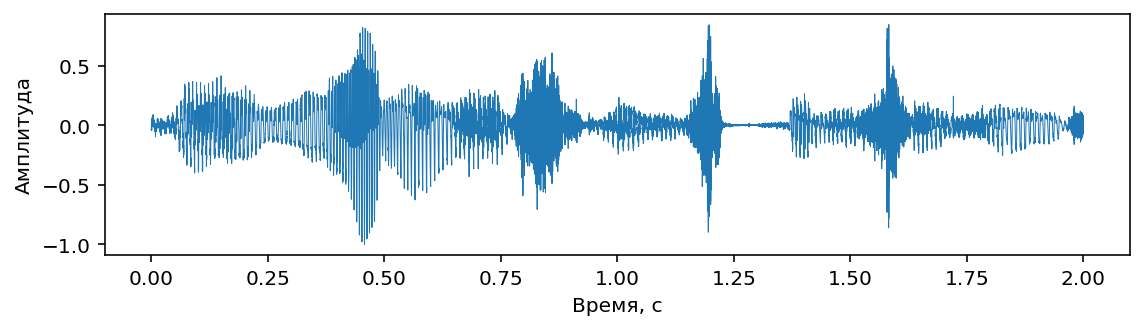

In [5]:
SR, LENGTH = 16000, 32000
def waveform(path):
    x,sr=sf.read(path,always_2d=True,dtype="float32")
    if len(x)<sr/4:
        raise ValueError("Нужно не менее 0,25 с звука.")
    x=x.mean(axis=1)
    if not np.isfinite(x).all() or np.max(np.abs(x))<1e-6:
        raise ValueError("Запись пуста или содержит тишину.")
    if sr!=SR:
        d=math.gcd(sr,SR)
        x=signal.resample_poly(x,SR//d,sr//d)
    start=max(0,(len(x)-LENGTH)//2)
    x=x[start:start+LENGTH]
    left=(LENGTH-len(x))//2
    x=np.pad(x,(left,LENGTH-len(x)-left))
    peak=np.max(np.abs(x))
    if peak<1e-6:
        raise ValueError("Центральный фрагмент содержит тишину.")
    return (x/peak).astype("float32")

def augment(x,rng):
    speed=rng.uniform(.97,1.03)
    shift=rng.integers(-1200,1201)
    t=np.arange(len(x))
    y=np.interp((t-shift)*speed,t,x,left=0,right=0)
    noise=rng.normal(0,np.sqrt(np.mean(y*y))*rng.uniform(.015,.04),len(x))
    return (y+noise).astype("float32")
x=waveform(RAW/df.file.iloc[0])
plt.figure(figsize=(8,2.4))
plt.plot(np.arange(LENGTH)/SR,x,lw=.5)
plt.xlabel("Время, с")
plt.ylabel("Амплитуда")
figure("wave.png")

## 6. Логарифмическая Mel-спектрограмма

Окно Ханна длиной 25 мс и шаг 10 мс дают локальные спектры мощности. 40 треугольных фильтров уплотняют представление на низких частотах. Нормирование по обучающим данным выполняется после разделения.

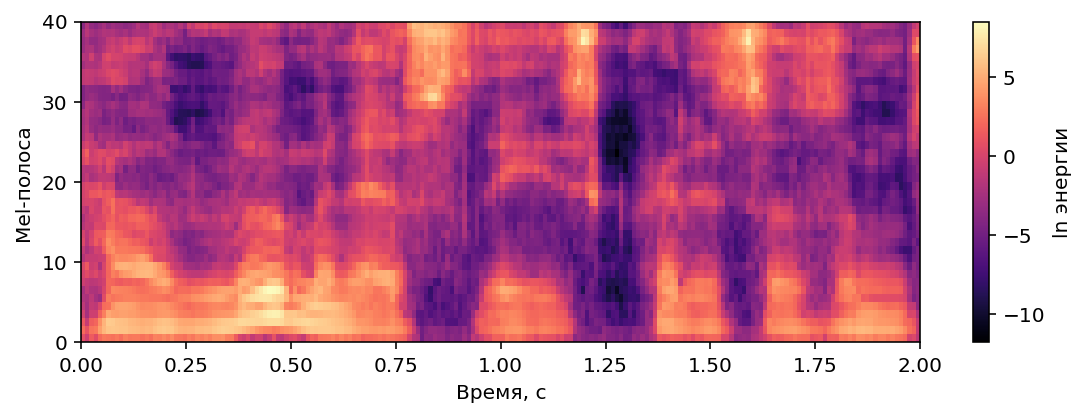

Размер массива: (480, 40, 198)


In [6]:
hz=np.linspace(0,SR/2,257)
edges=700*(10**(np.linspace(0,2595*np.log10(1+8000/700),42)/2595)-1)
filters=np.array([np.maximum(0,np.minimum((hz-a)/(b-a),(c-hz)/(c-b))) for a,b,c in zip(edges,edges[1:],edges[2:])],dtype="float32")
def features(x):
    frames=np.lib.stride_tricks.sliding_window_view(x,400)[::160]
    spec=np.abs(fft.rfft(frames*np.hanning(400).astype("float32"),n=512))**2
    return np.log(np.maximum(filters@spec.T,1e-8)).astype("float32")
X=np.stack([features(waveform(RAW/f)) for f in df.file])
y=(df.label=="M").astype("int64").to_numpy()
plt.figure(figsize=(8,3))
plt.imshow(X[0],origin="lower",aspect="auto",extent=[0,2,0,40],cmap="magma")
plt.xlabel("Время, с")
plt.ylabel("Mel-полоса")
plt.colorbar(label="ln энергии")
figure("mel.png")
print("Размер массива:", X.shape)

## 7. Независимые группы

Внутри каждой корпусной метки перемешиваем дикторов одним генератором. Контрольная проверка исключает пересечения между всеми тремя частями.

In [7]:
rng=np.random.default_rng(SEED)
for label,g in df.groupby("label"):
    ids=rng.permutation(sorted(g.speaker.unique()))
    train_end=round(.70*len(ids))
    val_end=train_end+round(.15*len(ids))
    for split,group in zip(["train","val","test"],np.split(ids,[train_end,val_end])):
        df.loc[df.speaker.isin(group),"split"]=split
assert df.groupby("speaker").split.nunique().max()==1 and df.split.notna().all()
df.to_csv(TAB/"manifest.csv",index=False)
idx={s:np.flatnonzero(df.split==s) for s in ["train","val","test"]}
tr,va,te=[idx[s] for s in ["train","val","test"]]
mu,sd=float(X[tr].mean()),float(X[tr].std())
def tensor(a):
    return torch.from_numpy((a-mu)/sd).unsqueeze(1)
aug=np.stack([features(augment(waveform(RAW/df.file[i]),rng)) for i in tr])
xt,yt=tensor(np.concatenate([X[tr],aug])),torch.tensor(np.tile(y[tr],2))
xv,yv=tensor(X[va]),torch.tensor(y[va])
display(df.groupby(["split","label"]).agg(фраз=("file","count"),дикторов=("speaker","nunique")))

фраз  дикторов
split label                
test  F        36         3
      M        36         3
train F       168        14
      M       168        14
val   F        36         3
      M        36         3

## 8. Архитектура

Два свёрточных блока выделяют локальные структуры. После усреднения остаются четыре частотные области, чтобы классификатор учитывал расположение энергии по частоте.

In [8]:
class Net(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.Conv2d(1,8,3,stride=(1,2),padding=1),nn.BatchNorm2d(8),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(8,16,3,padding=1),nn.BatchNorm2d(16),nn.ReLU(),nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4,1)),nn.Flatten(),nn.Linear(64,24),nn.ReLU(),
            nn.Dropout(.25),nn.Linear(24,2))
print(Net())

Net(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 2), padding=(1, 1))
  (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): AdaptiveAvgPool2d(output_size=(4, 1))
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=64, out_features=24, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.25, inplace=False)
  (13): Linear(in_features=24, out_features=2, bias=True)
)


## 9. Обучение и сохранение лучшей модели

Сопоставляем две скорости Adam при одинаковой инициализации и порядке батчей. После четырёх эпох без улучшения validation loss останавливаем запуск. Сохраняем веса эпохи с минимальной ошибкой валидации.

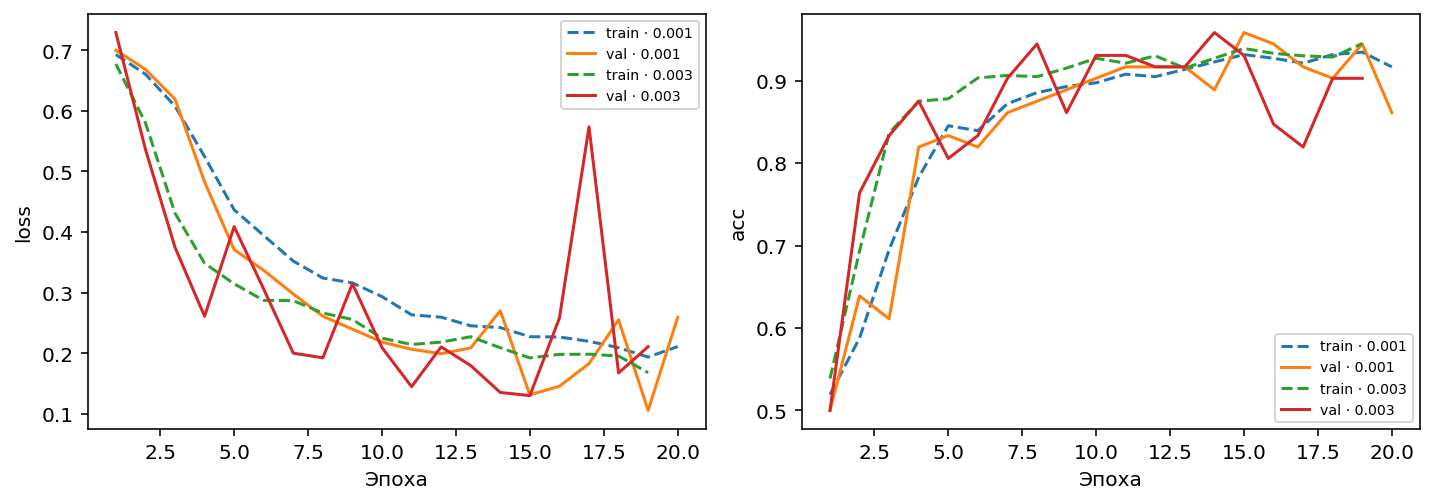

In [9]:
import copy
loss_fn=nn.CrossEntropyLoss()
history, runs, states=[],[],{}
for lr in [.003,.001]:
    torch.manual_seed(SEED)
    net=Net()
    opt=torch.optim.Adam(net.parameters(),lr=lr)
    best=float("inf")
    start=time.perf_counter()
    for epoch in range(1,21):
        net.train()
        total=hits=0
        for batch in torch.randperm(len(yt)).split(32):
            opt.zero_grad()
            logits=net(xt[batch])
            loss=loss_fn(logits,yt[batch])
            loss.backward()
            opt.step()
            total+=loss.item()*len(batch)
            hits+=(logits.argmax(1)==yt[batch]).sum().item()
        net.eval()
        with torch.no_grad():
            pred=net(xv)
            vl=loss_fn(pred,yv).item()
            acc=(pred.argmax(1)==yv).float().mean().item()
        history.append(dict(lr=lr,epoch=epoch,train_loss=total/len(yt),train_acc=hits/len(yt),val_loss=vl,val_acc=acc))
        if vl<best:
            best,best_epoch,best_acc=vl,epoch,acc
            states[lr]=copy.deepcopy(net.state_dict())
        if epoch-best_epoch>=4:
            break
    runs.append(dict(lr=lr,best_epoch=best_epoch,epochs=epoch,val_loss=best,val_acc=best_acc,seconds=time.perf_counter()-start))
hist=pd.DataFrame(history)
hist.to_csv(RES/"training_history.csv",index=False)
winner=min(runs,key=lambda r:r["val_loss"])
torch.save(dict(weights=states[winner["lr"]],mu=mu,sd=sd,classes=["F","M"]),MODEL)
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
for lr,g in hist.groupby("lr"):
    for ax,measure in zip(axes,["loss","acc"]):
        for split,style in [("train","--"),("val","-")]:
            ax.plot(g.epoch,g[f"{split}_{measure}"],style,label=f"{split} · {lr}")
        ax.set(xlabel="Эпоха",ylabel=measure)
        ax.legend(fontsize=7)
figure("history.png")

## 10. Сравнение конфигураций

Базовая модель SVM использует среднее и стандартное отклонение первых 13 MFCC. Масштабирование признаков подбирается только на обучающих записях. Сравнение на валидации предшествует обращению к тесту.

,lr,best_epoch,epochs,val_loss,val_acc,seconds
0,0.003,15,19,0.129967,0.930556,10.544654
1,0.001,19,20,0.105457,0.944444,10.483606


SVM, validation accuracy: 0.7638888888888888


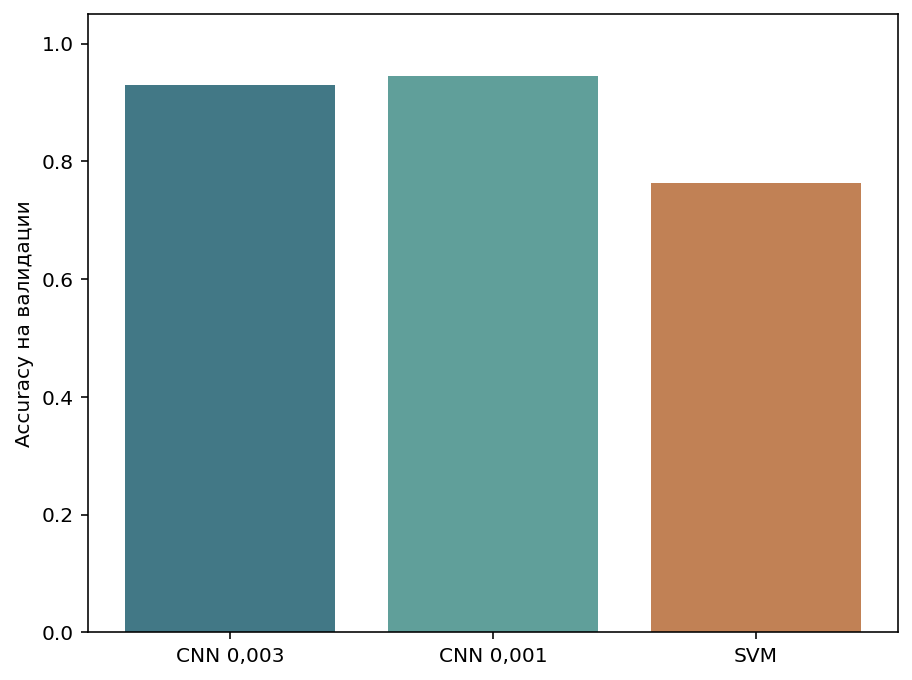

In [10]:
def mfcc_stats(z):
    cep=fft.dct(z,type=2,axis=1,norm="ortho")[:,:13]
    return np.c_[cep.mean(axis=2),cep.std(axis=2)]
svm=make_pipeline(StandardScaler(),SVC(C=1))
svm.fit(mfcc_stats(np.concatenate([X[tr],aug])),np.tile(y[tr],2))
svm_acc=svm.score(mfcc_stats(X[va]),y[va])
runs_df=pd.DataFrame(runs)
runs_df.to_csv(TAB/"experiments.csv",index=False)
display(runs_df)
print("SVM, validation accuracy:",svm_acc)
plt.bar(["CNN 0,003","CNN 0,001","SVM"],[r["val_acc"] for r in runs]+[svm_acc],color=["#427886","#609f9a","#c18155"])
plt.ylabel("Accuracy на валидации")
plt.ylim(0,1.05)
figure("comparison.png")

## 11. Независимое тестирование

Положительный класс для ROC — M. Для precision, recall и F1 приводим оценки по классам и невзвешенное среднее macro. Каждая фраза имеет одинаковый вес.

,precision,recall,f1-score,support
F,1.00,0.888889,0.941176,36.0
M,0.90,1.000000,0.947368,36.0
macro avg,0.95,0.944444,0.944272,72.0
weighted avg,0.95,0.944444,0.944272,72.0


Accuracy: 0.9444444444444444


,file,speaker,label,source,seconds,split,prediction,p_M,correct
0,1272-128104-0005.flac,1272,M,LibriSpeech/dev-clean/1272/128104/1272-128104-...,9.010000,test,M,0.995364,True
1,1272-128104-0006.flac,1272,M,LibriSpeech/dev-clean/1272/128104/1272-128104-...,5.640000,test,M,0.993507,True
2,1272-128104-0007.flac,1272,M,LibriSpeech/dev-clean/1272/128104/1272-128104-...,9.240000,test,M,0.984512,True
243,3576-138058-0011.flac,3576,F,LibriSpeech/dev-clean/3576/138058/3576-138058-...,11.280000,test,M,0.672694,False
248,3576-138058-0032.flac,3576,F,LibriSpeech/dev-clean/3576/138058/3576-138058-...,5.585063,test,M,0.537031,False
249,3576-138058-0034.flac,3576,F,LibriSpeech/dev-clean/3576/138058/3576-138058-...,8.065000,test,M,0.636876,False


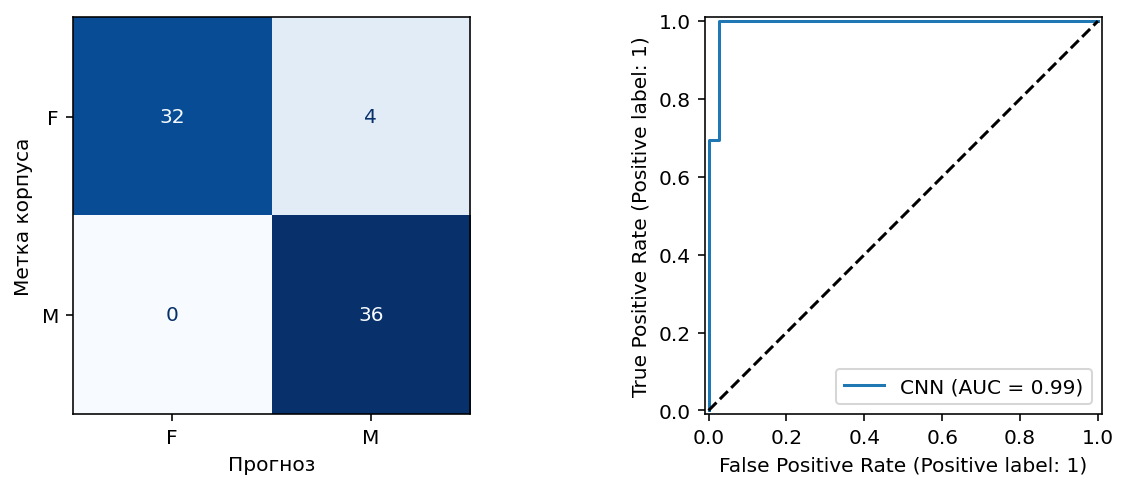

In [11]:
def load_model():
    ck=torch.load(MODEL,map_location="cpu",weights_only=True)
    net=Net()
    net.load_state_dict(ck["weights"])
    return net.eval(),ck
net,ck=load_model()
with torch.inference_mode():
    p=net(tensor(X[te])).softmax(1).numpy()
yp=p.argmax(1)
report=metrics.classification_report(y[te],yp,labels=[0,1],target_names=["F","M"],output_dict=True,zero_division=0)
class_table = pd.DataFrame({k:v for k,v in report.items() if isinstance(v,dict)}).T
class_table.to_csv(TAB/"classification_report.csv")
cm=metrics.confusion_matrix(y[te],yp,labels=[0,1])
auc=metrics.roc_auc_score(y[te],p[:,1])
scores=dict(accuracy=report["accuracy"],precision_macro=report["macro avg"]["precision"],recall_macro=report["macro avg"]["recall"],f1_macro=report["macro avg"]["f1-score"],roc_auc=auc,confusion_matrix=cm.tolist(),svm_validation_accuracy=svm_acc,svm_test_accuracy=svm.score(mfcc_stats(X[te]),y[te]),selected_lr=winner["lr"])
(RES/"metrics.json").write_text(json.dumps(scores,indent=2),encoding="utf8")
out=df.iloc[te].copy()
out["prediction"]=np.where(yp,"M","F")
out["p_M"]=p[:,1]
out["correct"]=yp==y[te]
out.to_csv(TAB/"predictions.csv",index=False)
display(class_table)
print("Accuracy:", report["accuracy"])
display(out.groupby("correct").head(3))
fig,ax=plt.subplots(1,2,figsize=(9,3.5))
metrics.ConfusionMatrixDisplay(cm,display_labels=["F","M"]).plot(ax=ax[0],colorbar=False,cmap="Blues")
ax[0].set(xlabel="Прогноз",ylabel="Метка корпуса")
metrics.RocCurveDisplay.from_predictions(y[te],p[:,1],ax=ax[1],name="CNN")
ax[1].plot([0,1],[0,1],"k--")
figure("test.png")

## 12. Прогноз по файлу

При демонстрации загружаем сохранённые веса и параметры нормирования. Числа softmax показывают относительную уверенность модели среди двух корпусных классов.

In [12]:
net,ck=load_model()
def predict(path):
    if not path or Path(path).suffix.lower() not in {".flac",".wav",".ogg"}:
        raise ValueError("Загрузите WAV, FLAC или OGG.")
    try:
        x=waveform(path)
    except (RuntimeError,OSError) as err:
        raise ValueError("Не удалось прочитать аудиофайл.") from err
    z=torch.from_numpy((features(x)-ck["mu"])/ck["sd"])[None,None]
    with torch.inference_mode():
        prob=net(z).softmax(1)[0].tolist()
    return dict(zip(["Женский голос (F)","Мужской голос (M)"],prob))
for i in [te[0],te[-1]]:
    print(df.file[i],predict(RAW/df.file[i]))

1272-128104-0005.flac {'Женский голос (F)': 0.004635869991034269, 'Мужской голос (M)': 0.9953640699386597}
8297-275155-0030.flac {'Женский голос (F)': 0.0027749568689614534, 'Мужской голос (M)': 0.9972250461578369}


## 13. Графический интерфейс

Интерфейс работает локально. Выберите файл и нажмите кнопку анализа. Для быстрого запуска без обучения служит demo.py в корне проекта.

In [13]:
import gradio as gr
def analyze(path):
    try:
        probs=predict(path)
        return max(probs,key=probs.get),probs
    except ValueError as err:
        return str(err),None
def build_gui():
    with gr.Blocks(title="Анализ записи · РГР 47") as gui:
        gr.Markdown("# Анализ речевой записи\nСравнение с метками M/F корпуса LibriSpeech. Используются центральные 2 секунды речи.")
        uploaded=gr.File(label="Аудиозапись · WAV, FLAC или OGG",type="filepath")
        action=gr.Button("Анализировать",variant="primary")
        result=gr.Textbox(label="Результат",interactive=False)
        probability=gr.Label(label="Вероятности модели",num_top_classes=2)
        action.click(analyze,uploaded,[result,probability])
    return gui
gui=build_gui()
gui.launch(server_name="127.0.0.1",share=False,prevent_thread_lock=True,inline=False)

c:\RGR\RGR_Variant_47\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 14. Выводы

Итоговая оценка относится к записям ранее не встречавшихся дикторов внутри dev-clean. Переносимость на другие языки, микрофоны и условия записи требует отдельного эксперимента. Метка корпуса не устанавливает пол или гендерную идентичность человека.

In [14]:
print(f"Тест: {len(te)} фраз, {df.iloc[te].speaker.nunique()} дикторов. Accuracy {scores['accuracy']:.3f}, macro-F1 {scores['f1_macro']:.3f}, AUC {auc:.3f}.")

Тест: 72 фраз, 6 дикторов. Accuracy 0.944, macro-F1 0.944, AUC 0.992.
